In [1]:
import numpy as np
import math
import distribution.distribution_functions.random_mps as rmps
import distribution.distribution_functions.different_distribution_random_states_and_matrices as distrib
from distribution.distribution_functions.kl_divergence_tools import compute_kl_divergence_from_samples

In [13]:
n = 4
t = 0
print(rmps.generate_angle_product_state_eigenvalues(n))
print(rmps.generate_angle_maximally_entangled_eigenvalues(n))
print(rmps.generate_angles_between_max_entangled_and_product_state_eigenvalues(n, t))

[0.         1.57079633 1.57079633]
[1.04719755 0.95531662 0.78539816]
[1.04719755 0.95531662 0.78539816]


In [4]:
n = 1
L = 4
d = 2
t = 0.1
diameter_disk = 0.1
print()

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)


array([ 0.02435867+0.j,  0.1253361 +0.j,  0.15678285+0.j, -0.40037997+0.j,
       -0.38244199+0.j,  0.10449669+0.j, -0.40978442+0.j, -0.11742697+0.j,
       -0.13993032+0.j,  0.37327577+0.j,  0.13759194+0.j,  0.12612588+0.j,
       -0.29254281+0.j, -0.22610819+0.j,  0.35902882+0.j, -0.02543314+0.j])

In [2]:
t = 0.5
n = 4
angles_center = rmps.generate_angles_between_max_entangled_and_product_state_eigenvalues(n, t)
diameter_disk = 0.1
for _ in range(0, 15):
    point = rmps.random_point_on_the_n_sphere_around_max_entangled_state(n, diameter_disk, angles_center, r=1)
    print(point)

[0.86585432 0.15130468 0.18249786 0.44056523]
[0.86626944 0.15120161 0.18232046 0.43985746]
[0.86603043 0.1513705  0.18239678 0.4402382 ]
[0.8659295  0.15153478 0.18253384 0.44032342]
[0.8662735  0.15120387 0.18229144 0.4398607 ]
[0.86587319 0.15131046 0.18262299 0.44047429]
[0.8659351  0.15126561 0.18239531 0.44046234]
[0.86589342 0.15163553 0.18228227 0.44046388]
[0.86623515 0.15144401 0.18240556 0.4398063 ]
[0.8662493  0.1512832  0.18204252 0.43998416]
[0.86588554 0.15171456 0.18262071 0.44031193]
[0.86579353 0.15149596 0.18256738 0.44059015]
[0.86611306 0.15131023 0.18250088 0.44005319]
[0.86602842 0.15148679 0.18242875 0.44018891]
[0.8661425  0.1512348  0.18243379 0.44004899]


In [2]:
L = 4
d = 2
t = 0.5
diameter_disk = 0.01
n = d**L
# rmps.generate_angle_maximally_entangled_eigenvalues(n)
rmps.produce_a_random_mps_eigenvalues_in_a_disk_center_moving(L, d, t, diameter_disk)

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)


([array([[[ 0.46539862, -0.88510144]],
  
         [[ 0.88510114,  0.46539874]]]),
  array([[[-0.27960747, -0.87322513,  0.26356387,  0.29966053],
          [ 0.0092634 , -0.1944174 , -0.94270646,  0.2709376 ]],
  
         [[-0.952134  ,  0.20261917, -0.10917669, -0.20149222],
          [ 0.12384966, -0.39820191, -0.17311902, -0.892302  ]]]),
  array([[[ 0.46731228,  0.22455522],
          [ 0.30386179,  0.56584447],
          [ 0.03466302,  0.23738824],
          [ 0.5937594 , -0.45297647]],
  
         [[-0.13035086,  0.37835651],
          [-0.11228774, -0.43207032],
          [-0.5229644 , -0.03661021],
          [-0.18012393,  0.19153814]]]),
  array([[[ 0.23175049],
          [-0.32414456]],
  
         [[ 0.85633566],
          [ 0.32849849]]])],
 [np.float64(5.643787242507437e-14),
  np.float64(0.007023934581322728),
  np.float64(0.11609182921179396),
  np.float64(0.0022310620110954434)],
 [np.float64(5.546350240730036e-07),
  np.float64(0.0003664949257967434),
  np.float64(2.

In [3]:
# The function 1 has the Haar measure distribution. 
d = 2
L = 4 

args_dict_1 = {"L": L, "d": d}
func1 = rmps.random_state_vector_from_mps

def compute_kl_divergence_from_fcts(func1, func2, args_dict_1, args_dict_2, n_samples=10000, bins=50, range_proba=None):
    """
    Computes the Kullback–Leibler divergence between two distributions generated by func1 and func2.
    
    Parameters:
        func1 (callable): A function generating a random number from distribution P.
        func2 (callable): A function generating a random number from distribution Q.
        args_dict_1 (dict): A dictionary of arguments to pass to func1.
        args_dict_2 (dict): A dictionary of arguments to pass to func2.
        n_samples (int): Number of samples to draw from each function.
        bins (int): Number of bins to use for the histogram.
        range (tuple): The range of the histograms (min, max).
        
    Returns:
        kl_div (float): The KL divergence D_KL(P || Q).
        samples1 (np.array): The samples from the function P.
        samples2 (np.array): The sampels fron the function Q.
    """    
    # Generates n_samples random state vectors of dimension n.
    samples1 = np.array([func1(**args_dict_1) for _ in range(n_samples)])
    samples2 = np.array([func2(**args_dict_2) for _ in range(n_samples)])
    
    # Create histograms
    hist1, bin_edges = np.histogram(samples1, bins=bins, range=range_proba, density=True)
    hist2, _ = np.histogram(samples2, bins=bin_edges, density=True)
    
    # Avoid divide-by-zero and log(0) by replacing zero probabilities with a small value
    hist1 = np.clip(hist1, 1e-10, None)
    hist2 = np.clip(hist2, 1e-10, None)
    
    # Compute KL divergence
    kl_div = np.sum(hist1 * np.log(hist1 / hist2))
    
    return kl_div, samples1, samples2

In [4]:
kl,  samp1, samp2 = compute_kl_divergence_from_fcts(func1, func1, args_dict_1, args_dict_1, n_samples=100, bins=50, range_proba=None)
    

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/_lib/array_api_compat/common/_aliases.py:235: ComplexWarning: Casting complex values to real discards the imaginary part
  return x.astype(dtype=dtype, copy=copy)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:851: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  db = np.array(np.diff(bin_edges), float)


In [9]:
bins = 50
hist1, bin_edges = np.histogram(samp1, bins=bins, range=None, density=True)
hist2, _ = np.histogram(samp2, bins=bin_edges, density=True)

/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:851: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  db = np.array(np.diff(bin_edges), float)


In [11]:
hist1, bin_edges


(array([0.0216386 , 0.0432772 , 0.06491581, 0.12983161, 0.08655441,
        0.19474742, 0.10819301, 0.32457903, 0.17310881, 0.32457903,
        0.47604924, 0.21638602, 0.60588085, 0.62751945, 0.86554407,
        0.71407386, 1.10356869, 1.08193009, 1.29831611, 1.2334003 ,
        1.25503891, 1.2117617 , 1.70944954, 1.38487052, 1.75272675,
        1.55797933, 1.57961793, 1.92583556, 1.2334003 , 1.44978632,
        1.31995471, 1.34159331, 1.06029149, 0.97373708, 0.69243526,
        0.56260365, 0.71407386, 0.62751945, 0.62751945, 0.32457903,
        0.34621763, 0.23802462, 0.28130182, 0.28130182, 0.12983161,
        0.12983161, 0.10819301, 0.0216386 , 0.0216386 , 0.06491581]),
 array([-0.73422321+0.j, -0.70533964+0.j, -0.67645607+0.j, -0.64757251+0.j,
        -0.61868894+0.j, -0.58980537+0.j, -0.56092181+0.j, -0.53203824+0.j,
        -0.50315467+0.j, -0.47427111+0.j, -0.44538754+0.j, -0.41650397+0.j,
        -0.38762041+0.j, -0.35873684+0.j, -0.32985327+0.j, -0.30096971+0.j,
        -0.272

In [3]:

kl = np.load("kl_divergence_result_Haar_measure_random_state_vs_mps_dirichlet_orthogonal.npy")
print(kl)

1.0062835655878555


In [11]:

try:
    # Load the samples
    samplesP = np.load("samplesP_Haar_measure_random_state2.npy")
    samplesQ = np.load("sampleesQ_mps_dirichlet_orthogonal.npy")
    # Compute KL divergence
    kl_div = compute_kl_divergence_from_samples(samplesP, samplesQ, bins=100, range_proba=[-5,5])
except FileNotFoundError:
    print(f"File not found. Skipping.")

print(kl_div)

1.0062835655878555


/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:851: ComplexWarning: Casting complex values to real discards the imaginary part
  indices = f_indices.astype(np.intp)
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/numpy/lib/_histograms_impl.py:894: ComplexWarning: Casting complex values to real discards the imaginary part
  db = np.array(np.diff(bin_edges), float)


In [10]:
print(samplesP.shape)

(10000, 16)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
import distribution.distribution_functions.different_distribution_random_states_and_matrices as distrib

In [ ]:


def generate_random_state(dim):
    """Generate a random state vector of given dimension."""
    state = np.random.randn(dim) + 1j * np.random.randn(dim)
    return state / np.linalg.norm(state)

def bipartition_and_svd(state, N):
    """Perform bipartition and SVD for each split of the state."""
    eigenvalue_distributions = []
    
    for n in range(1, N):
        dim_A, dim_B = n, N // n
        if N % n != 0:
            continue  # Ensure dimensions are compatible
        
        # Reshape into bipartition form
        reshaped_state = state.reshape(dim_A, dim_B)
        
        # Singular value decomposition
        _, singular_values, _ = svd(reshaped_state)
        eigenvalues = singular_values**2  # Eigenvalues of the reduced density matrix
        eigenvalue_distributions.append(eigenvalues)
    
    return eigenvalue_distributions

def plot_density_distributions(distributions):
    """Plot density distributions of eigenvalues."""
    for i, eigenvalues in enumerate(distributions):
        plt.hist(eigenvalues, bins=30, density=True, alpha=0.5, label=f"Bipartition {i+1}")
    
    plt.xlabel("Eigenvalue")
    plt.ylabel("Density")
    plt.legend()
    plt.title("Density Distribution of Eigenvalues")
    plt.show()

# Main script
N = 16  # Example dimension
state = (N)
eigenvalue_distributions = bipartition_and_svd(state, N)
plot_density_distributions(eigenvalue_distributions)


/tmp/ipykernel_2298567/1291203930.py:8: RuntimeWarning: invalid value encountered in arcsin
  y_values = np.arcsin((1 + a_values) / (1 - a_values))


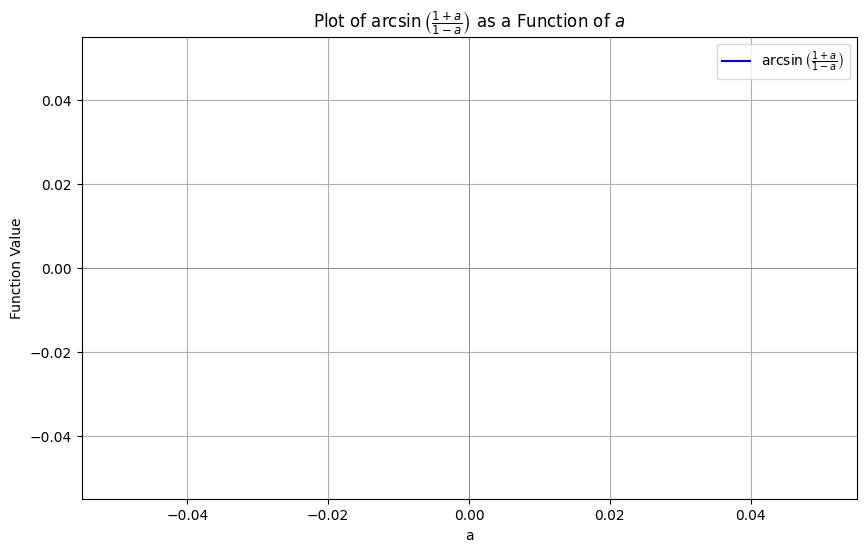

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Define the range of 'a' values, avoiding a = 1 to prevent division by zero
a_values = np.linspace(0.1, 0.99, 1000)

# Compute the corresponding arcsin values
y_values = np.arcsin((1 + a_values) / (1 - a_values))

# Plot the function
plt.figure(figsize=(10, 6))
plt.plot(a_values, y_values, label=r'$\arcsin\left(\frac{1+a}{1-a}\right)$', color='blue')
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('a')
plt.ylabel('Function Value')
plt.title(r'Plot of $\arcsin\left(\frac{1+a}{1-a}\right)$ as a Function of $a$')
plt.legend()
plt.grid(True)

plt.show()


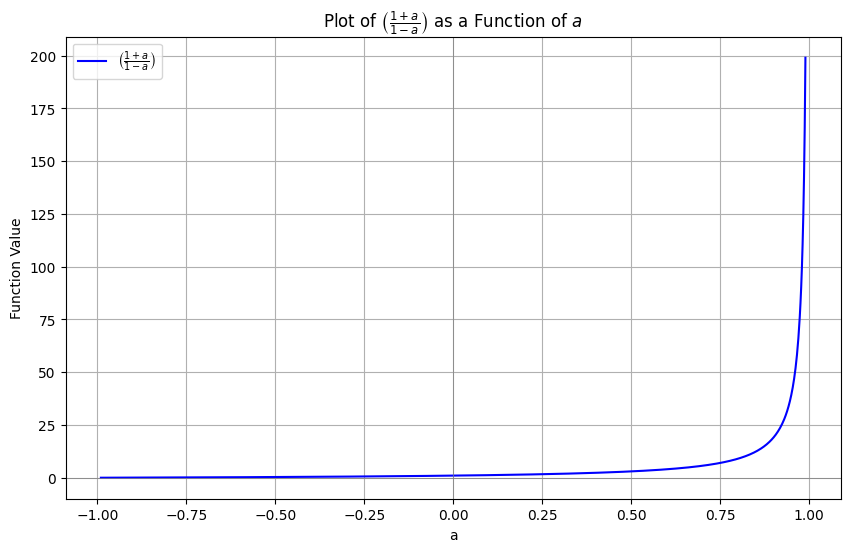

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Define the range of 'a' values, avoiding a = 1 to prevent division by zero
a_values = np.linspace(-0.99, 0.99, 1000)

# Compute the corresponding arcsin values
y_values = (1 + a_values) / (1 - a_values)

# Plot the function
plt.figure(figsize=(10, 6))
plt.plot(a_values, y_values, label=r'$\left(\frac{1+a}{1-a}\right)$', color='blue')
plt.axhline(0, color='gray', linewidth=0.5)
plt.axvline(0, color='gray', linewidth=0.5)
plt.xlabel('a')
plt.ylabel('Function Value')
plt.title(r'Plot of $\left(\frac{1+a}{1-a}\right)$ as a Function of $a$')
plt.legend()
plt.grid(True)

plt.show()


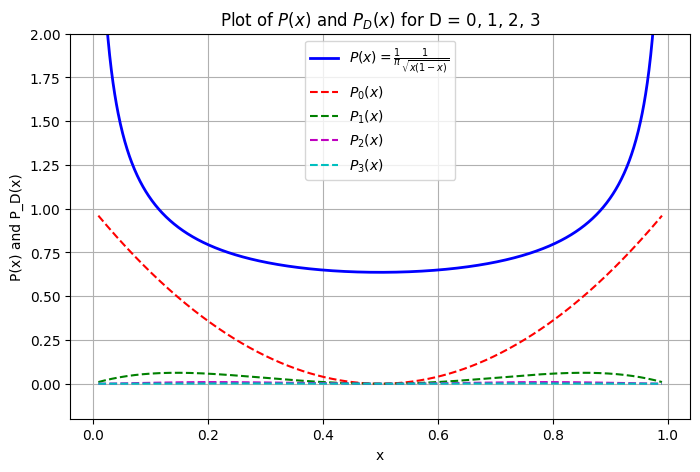

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define the main function P(x)
def P(x):
    return (1 / np.pi) * (1 / np.sqrt(x * (1 - x)))

# Define the family of functions P_D(x)
def P_D(x, D):
    return (1 - x)**D * x**D * (x - (1 - x))**2

# Define x values avoiding singularities at 0 and 1
x = np.linspace(0.01, 0.99, 1000)  # Avoid exact 0 and 1

# Compute P(x)
y_P = P(x)

# Plot P(x)
plt.figure(figsize=(8, 5))
plt.plot(x, y_P, label=r"$P(x) = \frac{1}{\pi} \frac{1}{\sqrt{x(1-x)}}$", color='b', linewidth=2)

# Plot P_D(x) for D = 0, 1, 2, 3
colors = ['r', 'g', 'm', 'c']
for i, D in enumerate([0, 1, 2, 3]):
    y_P_D = P_D(x, D)
    plt.plot(x, y_P_D, label=fr"$P_{{{D}}}(x)$", color=colors[i], linestyle='--')

# Labels and title
plt.xlabel("x")
plt.ylabel("P(x) and P_D(x)")
plt.title("Plot of $P(x)$ and $P_D(x)$ for D = 0, 1, 2, 3")
plt.ylim(-0.2, 2)  # Adjusting y-limits for better visualization
plt.legend()
plt.grid()
plt.show()


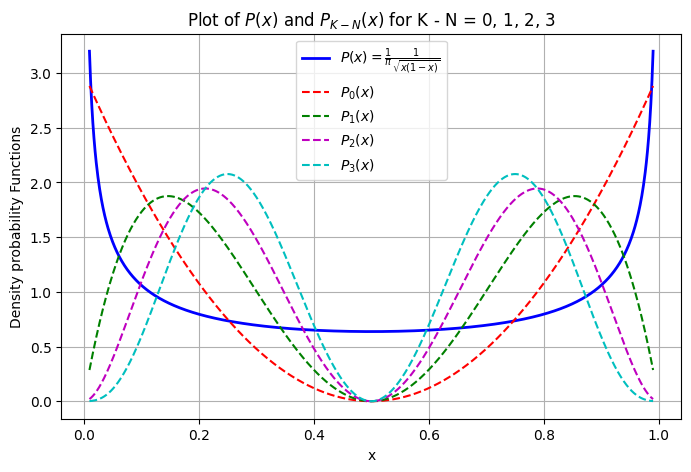

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P_D(x)
def P_D(x, D):
    return (1 - x)**D * x**D * (x - (1 - x))**2

# Compute normalization constant Z_D numerically
def compute_Z_D(D):
    integral, _ = quad(P_D, 0, 1, args=(D,))
    return integral

# Define the normalized probability density function
def P_D_normalized(x, D):
    Z_D = compute_Z_D(D)
    return P_D(x, D) / Z_D

# Define the main function P(x)
def P(x):
    return (1 / np.pi) * (1 / np.sqrt(x * (1 - x)))

# Define x values avoiding singularities at 0 and 1
x = np.linspace(0.01, 0.99, 1000)  # Avoid exact 0 and 1

# Compute P(x)
y_P = P(x)

# Plot P(x)
plt.figure(figsize=(8, 5))
plt.plot(x, y_P, label=r"$P(x) = \frac{1}{\pi} \frac{1}{\sqrt{x(1-x)}}$", color='b', linewidth=2)

# Plot normalized P_D(x) for D = 0, 1, 2, 3
colors = ['r', 'g', 'm', 'c']
for i, D in enumerate([0, 1, 2, 3]):
    y_P_D_norm = np.array([P_D_normalized(xi, D) for xi in x])
    plt.plot(x, y_P_D_norm, label=fr"$P_{{{D}}}(x)$", color=colors[i], linestyle='--')

# Labels and title
plt.xlabel("x")
plt.ylabel("Density probability Functions")
plt.title("Plot of $P(x)$ and $P_{K-N}(x)$ for K - N = 0, 1, 2, 3")
plt.legend()
plt.grid()
plt.show()


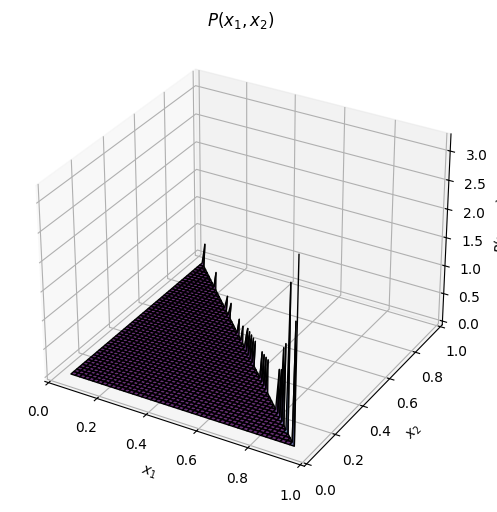

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the function P(x1, x2)
def P(x1, x2):
    with np.errstate(divide='ignore', invalid='ignore'):  # Handle singularities safely
        P_val = (1 / np.pi)**2 * (1 / np.sqrt(x1 * (1 - x1))) * (1 / np.sqrt(x2 * (1 - x1 - x2)))
        P_val[(x1 + x2) > 1] = np.nan  # Remove values where x1 + x2 > 1
    return P_val

# Define grid points for x1 and x2
N = 100  # Resolution
x1_vals = np.linspace(0.05, 0.95, N)  # Avoid exact singularities
x2_vals = np.linspace(0.05, 0.95, N)
X1, X2 = np.meshgrid(x1_vals, x2_vals)

# Compute P(x1, x2) while ensuring x1 + x2 <= 1
Z = P(X1, X2)

# Create a mask for the valid region (x1 + x2 <= 1)
# Z[np.isnan(Z)] = 0  # Replace NaNs for cleaner plotting
# Z[Z>0.5] =  np.nan  # Replace NaNs for cleaner plotting

# Plot in 3D
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X1, X2, Z, cmap='viridis', edgecolor='k', alpha=0.8)

# Labels
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_zlabel(r"$P(x_1, x_2)$")
ax.set_title(r"$P(x_1, x_2)$")

plt.show()


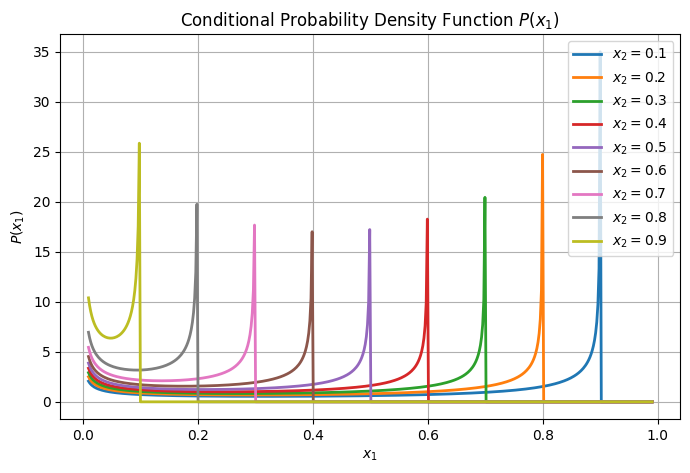

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P(x1, x2)
def P(x1, x2):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (1 / np.pi)**2 * (1 / np.sqrt(x1 * (1 - x1))) * (1 / np.sqrt(x2 * (1 - x1 - x2)))

# Compute the normalization constant Z(x2) numerically
def compute_Z(x2):
    integral, _ = quad(lambda x1: P(x1, x2), 0, 1 - x2)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2):
    Z_x2 = compute_Z(x2)
    return P(x1, x2) / Z_x2 if Z_x2 != 0 else 0  # Avoid division by zero

# Define x1 values avoiding singularities
x1_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x2 to plot
x2_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# Create the plot
plt.figure(figsize=(8, 5))

for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2) for x1 in x1_vals])  # Compute normalized P(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P(x_1)$")
plt.title(r"Conditional Probability Density Function $P(x_1)$")
plt.legend()
plt.grid()
plt.show()


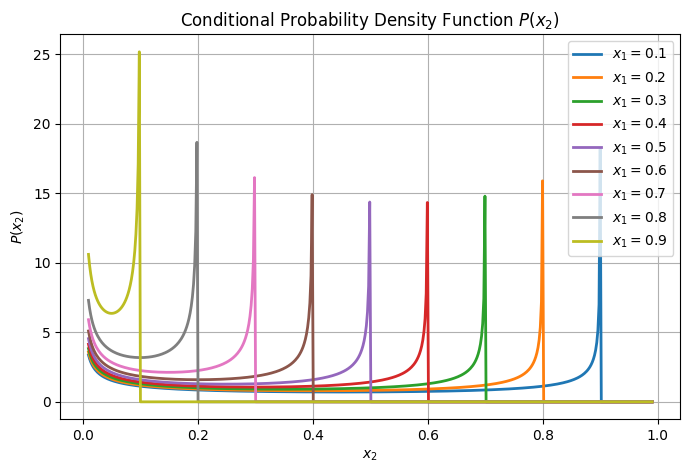

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P(x1, x2)
def P(x1, x2):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (1 / np.pi)**2 * (1 / np.sqrt(x1 * (1 - x1))) * (1 / np.sqrt(x2 * (1 - x1 - x2)))

# Compute the normalization constant Z(x1) numerically
def compute_Z(x1):
    integral, _ = quad(lambda x2: P(x1, x2), 0, 1 - x1)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2):
    Z_x1 = compute_Z(x1)
    return P(x1, x2) / Z_x1 if Z_x1 != 0 else 0  # Avoid division by zero

# Define x2 values avoiding singularities
x2_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x1 to plot
x1_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# Create the plot
plt.figure(figsize=(8, 5))

for x1 in x1_values:
    P_vals = np.array([P_normalized(x1, x2) for x2 in x2_vals])  # Compute normalized P(x2)
    plt.plot(x2_vals, P_vals, label=fr"$x_1 = {x1}$", linewidth=2)

# Labels and title
plt.xlabel(r"$x_2$")
plt.ylabel(r"$P(x_2)$")
plt.title(r"Conditional Probability Density Function $P(x_2)$")
plt.legend()
plt.grid()
plt.show()


In [11]:
print(Z)

[[2.19152885e+00 2.17416728e+00 2.15728323e+00 ... 4.81659076e+01
  6.86844187e+01 3.22216443e+08]
 [2.17313614e+00 2.15592136e+00 2.13918007e+00 ... 6.75113844e+01
  3.46887683e+08 0.00000000e+00]
 [2.15523647e+00 2.13816456e+00 2.12156223e+00 ... 4.40250720e+08
  0.00000000e+00 0.00000000e+00]
 ...
 [1.12473544e+01 1.57722505e+01            inf ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [1.58986101e+01            inf 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [           inf 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]]


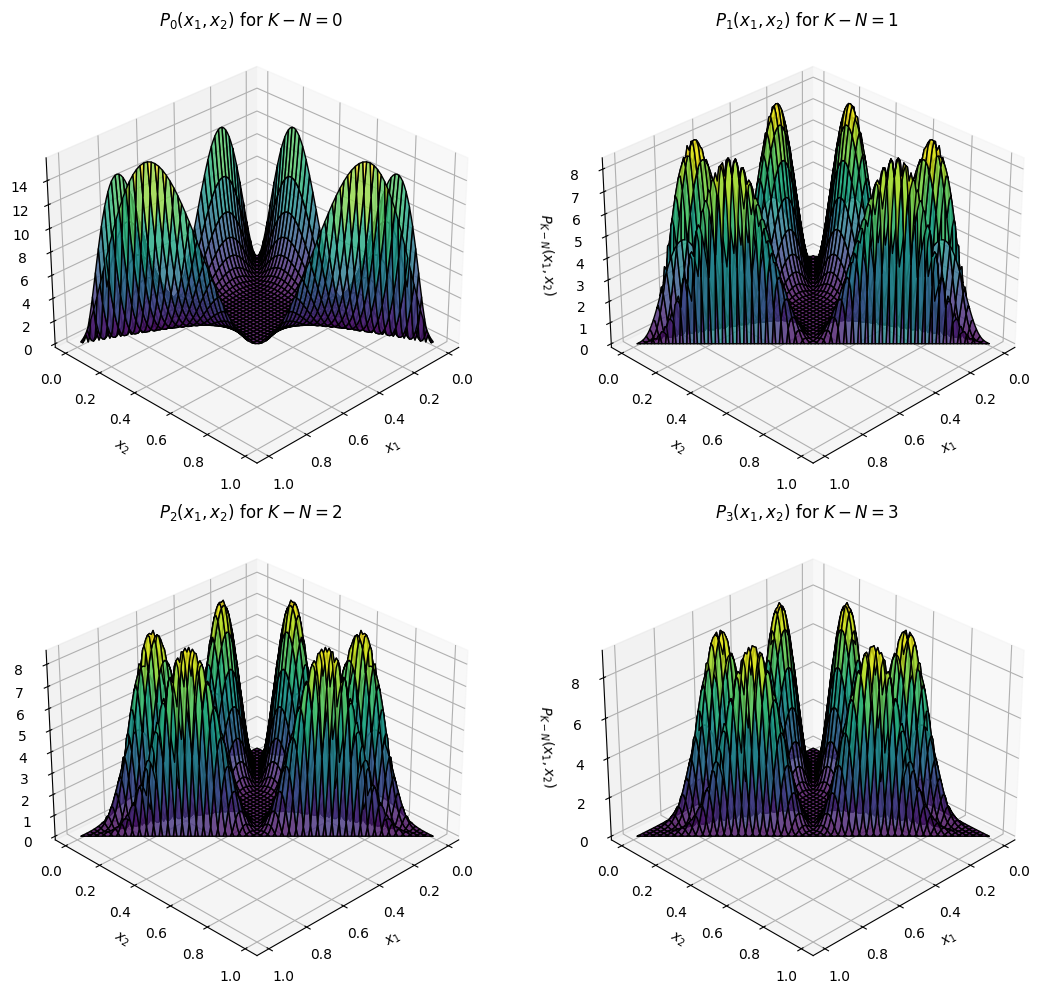

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import dblquad

# Define the unnormalized function P_D(x1, x2)
def P_D(x1, x2, D):
    if (x1 + x2) > 1:
        return 0  # Ensure function is zero outside valid region
    return ((1 - x1 - x2)**D * x1**D * x2**D *
            (x1 - x2)**2 * (x1 - (1 - x1 - x2))**2 * (x2 - (1 - x1 - x2))**2)

# Compute the normalization constant Z_D numerically
def compute_Z_D(D):
    integral, _ = dblquad(lambda x2, x1: P_D(x1, x2, D), 0, 1, lambda x1: 0, lambda x1: 1 - x1)
    return integral

# Define the normalized probability density function
def P_D_normalized(x1, x2, D):
    Z_D = compute_Z_D(D)
    return P_D(x1, x2, D) / Z_D if Z_D != 0 else 0  # Avoid division by zero

# Define grid points for x1 and x2
N = 100  # Resolution for smoother plots
x1_vals = np.linspace(0.01, 0.99, N)  # Avoid exact singularities
x2_vals = np.linspace(0.01, 0.99, N)
X1, X2 = np.meshgrid(x1_vals, x2_vals)

# Plot for D = 0, 1, 2, 3
fig, axes = plt.subplots(2, 2, subplot_kw={'projection': '3d'}, figsize=(12, 10))

D_values = [0, 1, 2, 3]
for i, D in enumerate(D_values):
    ax = axes[i // 2, i % 2]
    
    # Compute normalized P_D(x1, x2) while ensuring x1 + x2 <= 1
    Z = np.array([[P_D_normalized(x1, x2, D) for x1, x2 in zip(x1_row, x2_row)] for x1_row, x2_row in zip(X1, X2)])

    # Mask out invalid values
    Z[(X1 + X2) > 1] = np.nan

    # Plot the surface
    surf = ax.plot_surface(X1, X2, Z, cmap='viridis', edgecolor='k', alpha=0.8)

    # Labels and title
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_zlabel(r"$P_{K-N}(x_1, x_2)$")
    ax.set_title(fr"$P_{D}(x_1, x_2)$ for $K-N={D}$")
    ax.view_init(elev=30, azim=45)  # Adjust initial view angle

# Show the plots
plt.tight_layout()
plt.show()


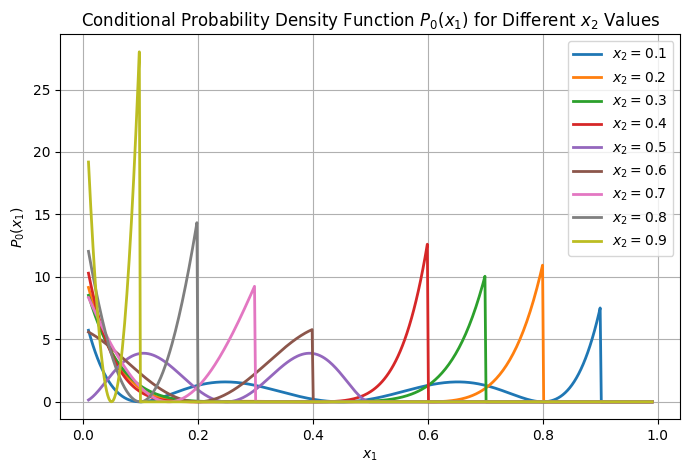

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P_D(x1, x2) for D=0
def P_D(x1, x2):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (x1 - x2)**2 * (x1 - (1 - x1 - x2))**2 * (x2 - (1 - x1 - x2))**2

# Compute the normalization constant Z(x2) numerically
def compute_Z(x2):
    integral, _ = quad(lambda x1: P_D(x1, x2), 0, 1 - x2)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2):
    Z_x2 = compute_Z(x2)
    return P_D(x1, x2) / Z_x2 if Z_x2 != 0 else 0  # Avoid division by zero

# Define x1 values avoiding singularities
x1_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x2 to plot
x2_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

# Create the plot
plt.figure(figsize=(8, 5))

for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2) for x1 in x1_vals])  # Compute normalized P(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P_0(x_1|x_2)$")
plt.title(r"Conditional Probability Density Function $P_0(x_1|x_2)$ for Different $x_2$ Values")
plt.legend()
plt.grid()
plt.show()


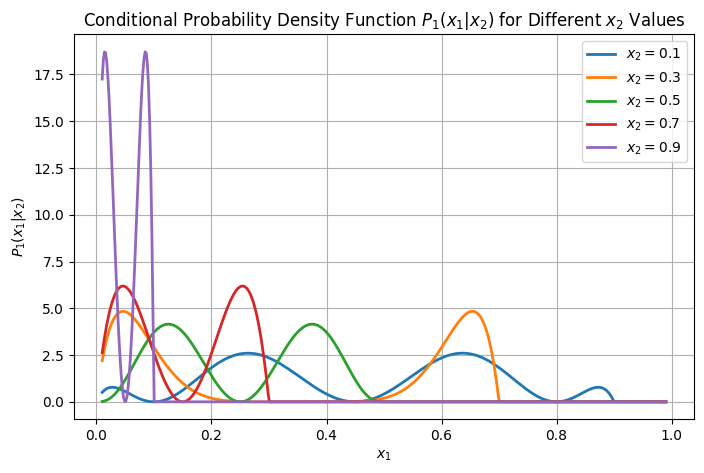

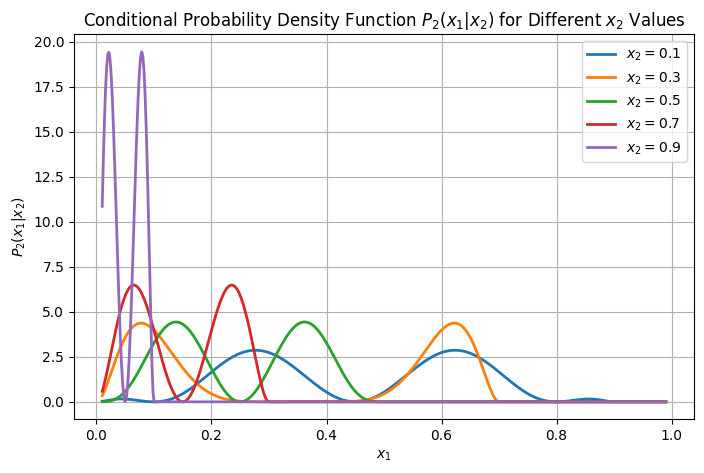

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the unnormalized function P_D(x1, x2)
def P_D(x1, x2, D):
    if x1 + x2 > 1 or x1 <= 0 or x2 <= 0 or (1 - x1 - x2) <= 0:
        return 0  # Ensure function is zero outside valid region
    return (1 - x1 - x2)**D * x1**D * x2**D * (x1 - x2)**2 * (x1 - (1 - x1 - x2))**2 * (x2 - (1 - x1 - x2))**2

# Compute the normalization constant Z(x2) numerically
def compute_Z(x2, D):
    integral, _ = quad(lambda x1: P_D(x1, x2, D), 0, 1 - x2)
    return integral

# Define the normalized probability density function
def P_normalized(x1, x2, D):
    Z_x2 = compute_Z(x2, D)
    return P_D(x1, x2, D) / Z_x2 if Z_x2 != 0 else 0  # Avoid division by zero

# Define x1 values avoiding singularities
x1_vals = np.linspace(0.01, 0.99, 500)  # Avoid exact 0 and 1

# Different values of x2 to plot
x2_values = [ 0.1,  0.3, 0.5,  0.7, 0.9]

# Plot for D = 1
plt.figure(figsize=(8, 5))
for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2, D=1) for x1 in x1_vals])  # Compute normalized P_D(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title for D=1
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P_1(x_1|x_2)$")
plt.title(r"Conditional Probability Density Function $P_1(x_1|x_2)$ for Different $x_2$ Values")
plt.legend()
plt.grid()
plt.show()

# Plot for D = 2
plt.figure(figsize=(8, 5))
for x2 in x2_values:
    P_vals = np.array([P_normalized(x1, x2, D=2) for x1 in x1_vals])  # Compute normalized P_D(x1)
    plt.plot(x1_vals, P_vals, label=fr"$x_2 = {x2}$", linewidth=2)

# Labels and title for D=2
plt.xlabel(r"$x_1$")
plt.ylabel(r"$P_2(x_1|x_2)$")
plt.title(r"Conditional Probability Density Function $P_2(x_1|x_2)$ for Different $x_2$ Values")
plt.legend()
plt.grid()
plt.show()


In [4]:
import numpy as np
from scipy.integrate import quad

# Define the probability density function P(x)
def P(x):
    if x <= 0 or x >= 1:
        return 0  # Ensure P(x) is valid in [0,1]
    return (1 / np.pi) * (1 / np.sqrt(x * (1 - x)))

# Define the entropy function H = - ∫ P(x) log P(x) dx
def entropy_integrand(x):
    px = P(x)
    return -px * np.log2(px) if px > 0 else 0  # Avoid log(0)

# Compute the Shannon entropy numerically
entropy, _ = quad(entropy_integrand, 0, 1)

# Print the result
print(f"Shannon Entropy H = {entropy:.6f} (in bits)")

Shannon Entropy H = -0.348504 (in bits)


In [5]:
import numpy as np
from scipy.integrate import quad

# Define the unnormalized function P_D(x)
def P_D(x, D):
    if x <= 0 or x >= 1:
        return 0  # Ensure P(x) is within [0,1]
    return (1 - x)**D * x**D * (x - (1 - x))**2

# Compute the normalization constant Z(D)
def compute_Z(D):
    integral, _ = quad(lambda x: P_D(x, D), 0, 1)
    return integral

# Compute the normalized probability density function
def P_normalized(x, D):
    Z_D = compute_Z(D)
    return P_D(x, D) / Z_D if Z_D != 0 else 0  # Avoid division by zero

# Compute Shannon entropy
def entropy_D(D):
    Z_D = compute_Z(D)  # Get normalization constant

    def entropy_integrand(x):
        p_x = P_D(x, D) / Z_D  # Normalized P_D(x)
        return -p_x * np.log2(p_x) if p_x > 0 else 0  # Avoid log(0)

    entropy, _ = quad(entropy_integrand, 0, 1)
    return entropy

# Compute and print entropy for D = 0,1,2,3
for D in range(4):
    H_D = entropy_D(D)
    print(f"Shannon Entropy for D={D}: H_{D} = {H_D:.6f} (in bits)")


Shannon Entropy for D=0: H_0 = -0.623166 (in bits)
Shannon Entropy for D=1: H_1 = -0.386446 (in bits)
Shannon Entropy for D=2: H_2 = -0.418331 (in bits)
Shannon Entropy for D=3: H_3 = -0.491172 (in bits)


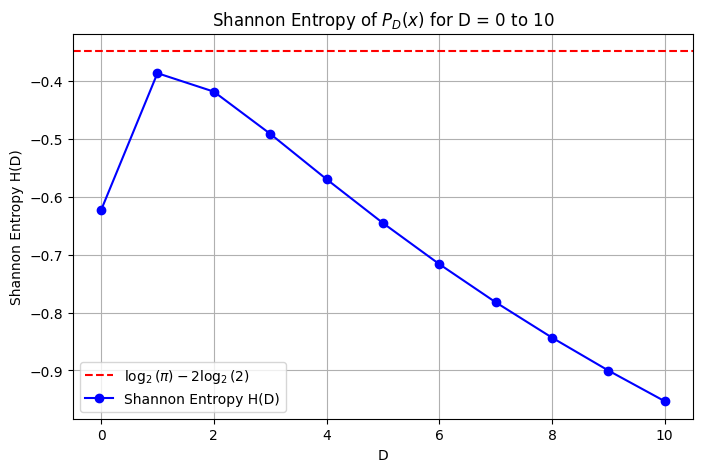

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Define the probability density function (before normalization)
def P_D(x, D):
    if x <= 0 or x >= 1:
        return 0  # Ensure P_D(x) is zero outside [0,1]
    return (1-x)**D * x**D * (x - (1-x))**2

# Compute the normalization constant Z(D)
def Z_D(D):
    integral, _ = quad(P_D, 0, 1, args=(D))
    return integral

# Normalized probability density function
def P_D_norm(x, D):
    return P_D(x, D) / Z_D(D)

# Compute Shannon entropy for given D
def shannon_entropy(D):
    def entropy_integrand(x):
        p = P_D_norm(x, D)
        return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

    entropy, _ = quad(entropy_integrand, 0, 1)
    return entropy

# Compute entropies for D from 0 to 10
D_values = np.arange(0, 11)
H_values = [shannon_entropy(D) for D in D_values]
H_analytic = np.log2(np.pi) - 2 * np.log2(2)
# Plot the entropy as a function of D
plt.figure(figsize=(8, 5))
plt.axhline(y=H_analytic, color='r', linestyle='--', label=r'$\log_2(\pi) - 2\log_2(2)$')
plt.plot(D_values, H_values, marker='o', linestyle='-', color='b', label='Shannon Entropy H(D)')
plt.xlabel("D")
plt.ylabel("Shannon Entropy H(D)")
plt.title("Shannon Entropy of $P_D(x)$ for D = 0 to 10")
plt.grid()
plt.legend()
plt.show()


In [6]:
print(-2*np.log2(2)+np.log2(np.pi))

-0.3485038705276813


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt, log2
from scipy.integrate import nquad

In [3]:
def func(x2, x1):
    if x1+x2>=1 or x1==0 or x2==0:
        return 0
    return 1/(np.pi**2*sqrt(x1*(1-x1)*x2*(1-x1-x2)))

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]

# Define the Shannon entropy function H_n
def entropy_integrand(*x):
    p = func(*x)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

h, abserror = nquad(entropy_integrand, [lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


-2.697007739743045


In [2]:
def func(x3, x2, x1):
    if x1+x2+x3>=1 or x1==0 or x2==0 or x3==0:
        return 0
    return 1/(np.pi**3*sqrt(x1*(1-x1)*x2*(1-x1-x2)*x3*(1-x1-x2-x3)))

def lim3(x2, x1):
    return [0, 1-x1-x2]

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]

# Define the Shannon entropy function H_n
def entropy_integrand(*x):
    p = func(*x)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

h, abserror = nquad(entropy_integrand, [lim3, lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/integrate/_quadpack_py.py:1272: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,
/scratch/h/H.Albot/distribution/.venv/lib64/python3.9/site-packages/scipy/integrate/_quadpack_py.py:1272: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be u

-7.045511675575186


In [3]:
print((h-3*log2(np.pi)))

-12.000000063992143


In [5]:
def func(x4, x3, x2, x1):
    if x1+x2+x3+x4>=1 or x1==0 or x2==0 or x3==0 or x4==0:
        return 0
    return 1/(np.pi**3*sqrt(x1*(1-x1)*x2*(1-x1-x2)*x3*(1-x1-x2-x3)*x4*(1-x1-x2-x3-x4)))

def lim4(x3,x2,x1):
    return [0, 1-x1-x2-x3]
    
def lim3(x2, x1):
    return [0, 1-x1-x2]

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]

# Define the Shannon entropy function H_n
def entropy_integrand(*x):
    p = func(*x)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)

h, abserror = nquad(entropy_integrand, [lim4, lim3, lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


KeyboardInterrupt: 

In [41]:
# Define the probability density function P(x_1, ..., x_{n-1})
def P(*x, n):
    x = x[0]
    if np.sum(x)>1:
        return 0
    sum_x = 0 
    prod = 1
    for k in range(n-1):
        if x[k]<0:
            return 0
        sum_x += x[k]
        prod *= (1 / np.pi) / np.sqrt(x[k] * (1 - sum_x))
    return prod
# x = 0.1, 0.2, 0.3
# print(P(x, n=4))

# Create a list of lim
def create_limite(n):
    return [0,1]

0.8294199674100734


In [ ]:
def generate_limits(n):
    limits = []

    # lim_0 (no arguments)
    def lim_0():
        return [0, 1]

    limits.append(lim_0)

    # lim_k (depends on x1, ..., xk)
    for k in range(1, n + 1):
        def lim_k(*args, k=k):  # Use default k to avoid late binding issue
            return [0, 1 - sum(args)]
        
        limits.append(lim_k)

    return limits


In [31]:

# Define the Shannon entropy function H_n
def entropy_integrand(*x, n):
    p = P(*x, n)
    return -p * np.log2(p) if p > 0 else 0  # Avoid log(0)


# Function to compute Shannon entropy for a given n
def compute_entropy(n):
    # Define bounds dynamically based on previous integration values
    def f(*x): 
        return entropy_integrand(*x, n=n)

    # Generate the integration bounds for each variable
    # print(integration_limits)
    # Compute the entropy via numerical integration using lambda
    H_n, _ = nquad(f, ranges=[[0,1],[0,1]])
    # H_n, _ = nquad(lambda *x: 1, ranges=[[0,1],[0,1]])
    return H_n
print(compute_entropy(3))
# # Compute and plot Shannon entropy for different values of n
# n_values = range(2, 10)  # From n=2 to n=9 (since we use n-1 dimensions)
# H_values = [compute_entropy(n) for n in n_values]

# plt.figure(figsize=(8, 5))
# plt.plot(n_values, H_values, marker='o', linestyle='-', color='b', label=r'$H_n$')
# plt.xlabel("n")
# plt.ylabel("Shannon Entropy $H_n$")
# plt.title("Shannon Entropy as a Function of n")
# plt.grid(True)
# plt.legend()
# plt.show()

# # Print computed values
# for n, H in zip(n_values, H_values):
#     print(f"n = {n}, H_n = {H:.6f}")


0.2


In [26]:
def bounds(*args):
    sum_x = np.sum(args) if args else 0
    return (0, 1 - sum_x)
argument = np.array([0.5,0.4])
bounds(argument)


(0, np.float64(0.09999999999999998))

In [1]:
import numpy as np
from scipy.integrate import quad

def integrand(x):
    if x == 0:
        return 0  # To avoid singularity at x=0
    return (x * np.log2(x)) / (np.pi * np.sqrt(x * (1 - x)) )

# Compute the integral numerically
F1, error = quad(integrand, 0, 1)

print(f"Computed integral F1: {F1:.8f}")


Computed integral F1: -0.27865248


In [3]:
print(-1+1/(2*np.log(2)))

-0.2786524795555183


In [6]:
import numpy as np
from scipy.integrate import nquad

def integrand2(x2, x1):
    if x1+x2>=1 or x1==0 or x2==0:
        return 0
    return x2*np.log2(x2)/(np.pi**2*np.sqrt(x1*(1-x1)*x2*(1-x1-x2)))


def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]


h, abserror = nquad(integrand2, [lim2, lim1])

                # opts=[opts0, opts1, opts2])
print(h)


-0.27865247955574973


In [5]:
import numpy as np
from scipy.integrate import nquad

def integrand(x3, x2, x1):
    if x1+x2+x3>=1 or x1==0 or x2==0 or x3==0:
        return 0
    return x3*np.log2(x3)/(np.pi**3*np.sqrt(x1*(1-x1)*x2*(1-x1-x2)*x3*(1-x1-x2-x3)))

    
def lim3(x2, x1):
    return [0, 1-x1-x2]

def lim2(x1):
    return [0, 1-x1]
lim1 = [0, 1]



h, abserror = nquad(integrand, [lim3, lim2, lim1])

                # opts=[opts0, opts1, opts2])

print(f"Computed integral F1: {h:.8f}")
a = 1/(2*np.log(2))-1 
print(f"Computed results analytic F1: {2*a/2**2:.8f}")


In [2]:
import numpy as np
a = 4*np.log(2)-2 
print(a)

0.7725887222397811
